All libraries imported successfully!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   

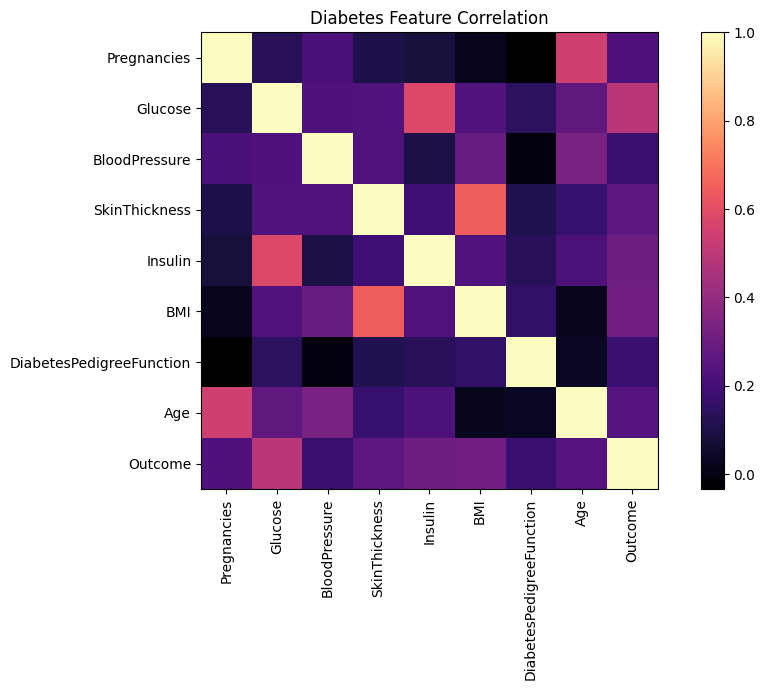

Training data: (614, 8)
Testing data: (154, 8)
Missing values handled successfully!
Data normalization completed!
Logistic Regression training completed!
Random Forest training completed!
Logistic Regression Accuracy: 70.78 %
Random Forest Accuracy: 77.27 %

Best Model: Random Forest
Best Accuracy: 77.27 %
Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.80      0.86      0.83       100
    Diabetic       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



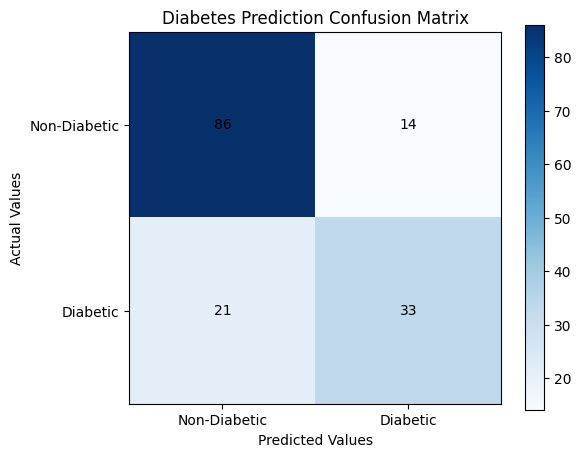

DIABETES RISK PREDICTION
------------------------
Result: Non-Diabetic class
Model probability for diabetic class: 46.0 %


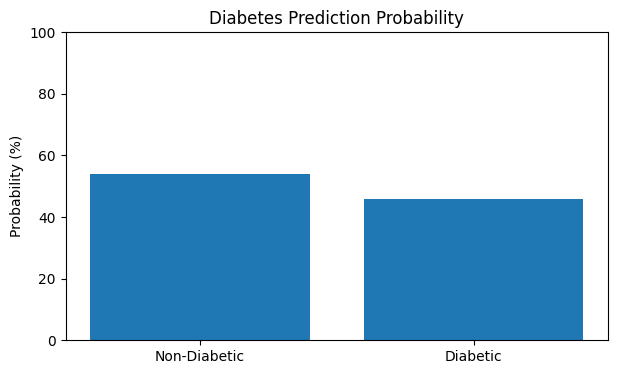

Project model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

print("All libraries imported successfully!")


# Load the diabetes dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]
df = pd.read_csv(url, names=columns)

# Display first five rows

print(df.head())

# Display dataset information

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())


# Check dataset details

print("Dataset Description:")
print(df.describe())

print("\nDiabetes Count:")
print(df['Outcome'].value_counts())

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())


# Replace incorrect zero values with missing values

columns_to_clean = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

for column in columns_to_clean:
    df[column] = df[column].replace(0, np.nan)

print("Missing values after cleaning:")
print(df.isnull().sum())

# Separate input and output columns

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("\nData preprocessing completed!")


# Calculate correlation

correlation = df.corr()

# Display correlation graph

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap='magma')
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Diabetes Feature Correlation")
plt.tight_layout()
plt.show()


# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# Fill missing values using median

imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scale the data

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Missing values handled successfully!")
print("Data normalization completed!")


# Create Logistic Regression model

logistic_model = LogisticRegression(max_iter=1000)

# Train the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

# Create Random Forest model

random_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model

random_model.fit(X_train, y_train)

print("Random Forest training completed!")


# Make predictions

logistic_prediction = logistic_model.predict(X_test)
random_prediction = random_model.predict(X_test)

# Calculate accuracy

logistic_accuracy = accuracy_score(
    y_test, logistic_prediction
)

random_accuracy = accuracy_score(
    y_test, random_prediction
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(random_accuracy * 100, 2), "%")

# Compare models

if logistic_accuracy >= random_accuracy:
    best_model = logistic_model
    best_name = "Logistic Regression"
else:
    best_model = random_model
    best_name = "Random Forest"

print("\nBest Model:", best_name)
print("Best Accuracy:", round(max(logistic_accuracy, random_accuracy) * 100, 2), "%")


# Predict using the best model

final_prediction = best_model.predict(X_test)

# Display classification report

print("Classification Report:")

print(classification_report(
    y_test,
    final_prediction,
    target_names=['Non-Diabetic', 'Diabetic']
))


# Calculate confusion matrix

cm = confusion_matrix(y_test, final_prediction)

# Display confusion matrix

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')

plt.title("Diabetes Prediction Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.yticks([0, 1], ['Non-Diabetic', 'Diabetic'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center')

plt.colorbar()
plt.show()



# Enter patient information

patient = pd.DataFrame([{
    'Pregnancies': 2,
    'Glucose': 140,
    'BloodPressure': 80,
    'SkinThickness': 25,
    'Insulin': 100,
    'BMI': 30.5,
    'DiabetesPedigreeFunction': 0.5,
    'Age': 35
}])

# Preprocess patient data

patient_data = imputer.transform(patient)

patient_data = scaler.transform(patient_data)

# Make prediction

prediction = best_model.predict(patient_data)

probability = best_model.predict_proba(patient_data)

print("DIABETES RISK PREDICTION")
print("------------------------")

if prediction[0] == 1:
    print("Result: Diabetic class")
else:
    print("Result: Non-Diabetic class")

print("Model probability for diabetic class:",
      round(probability[0][1] * 100, 2), "%")



# Get prediction probabilities

probability = best_model.predict_proba(patient_data)[0]

labels = ['Non-Diabetic', 'Diabetic']

# Display graph

plt.figure(figsize=(7, 4))

plt.bar(labels, probability * 100)

plt.title("Diabetes Prediction Probability")
plt.ylabel("Probability (%)")
plt.ylim(0, 100)

plt.show()



# Import joblib

import joblib

# Save all required objects

project_model = {
    'imputer': imputer,
    'scaler': scaler,
    'model': best_model
}

joblib.dump(
    project_model,
    'diabetes_prediction_model.pkl'
)

print("Project model saved successfully!")


# Download the trained model

from google.colab import files

files.download('diabetes_prediction_model.pkl')





